<a href="https://colab.research.google.com/github/Onyinyenwakozor/erc4626_vault_flows/blob/main/erc4626_vault_flows.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [111]:
!pip install -q requests pandas numpy scikit-learn matplotlib
import requests, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

In [112]:
pools = pd.DataFrame(requests.get("https://yields.llama.fi/pools", timeout=60).json()["data"])

NAMES = {"morpho-blue": "Morpho", "yearn-finance": "Yearn", "euler-v2": "Euler"}

cands = pools[
    (pools.chain == "Ethereum")
    & (pools.project.isin(NAMES.keys()))
    & (pools.symbol.str.contains("USDC"))
    & (pools.tvlUsd > 1_000_000)
    & (pools.apyBase > 0)                      # skip vaults with no base yield
].sort_values("tvlUsd", ascending=False)

# top 3 per protocol, to see the options
display(cands.groupby("project").head(3)[["pool", "project", "symbol", "tvlUsd", "apyBase"]])

VAULTS = {
    "Steakhouse Prime Instant": "931ea9be-5f4d-428e-beaf-205fc5b4e2b5",
    "Gauntlet USDC Prime": "71b34441-5a46-431b-a9b3-8c081cd0d74c",
    "kpk USDC Prime": "052e3f85-e489-4bee-9e34-c7898ef1d449",
}
print(VAULTS)


,pool,project,symbol,tvlUsd,apyBase
143,931ea9be-5f4d-428e-beaf-205fc5b4e2b5,morpho-blue,STEAKUSDC,130166945,4.60687
164,71b34441-5a46-431b-a9b3-8c081cd0d74c,morpho-blue,GTUSDCP,104191632,4.58611
240,b55f43a8-f444-4cd8-a3a4-0a4e786ba566,morpho-blue,STEAKUSDC,68441540,4.37658


{'Steakhouse Prime Instant': '931ea9be-5f4d-428e-beaf-205fc5b4e2b5', 'Gauntlet USDC Prime': '71b34441-5a46-431b-a9b3-8c081cd0d74c', 'kpk USDC Prime': '052e3f85-e489-4bee-9e34-c7898ef1d449'}


In [113]:
def get_chart(pool_id):
    resp = requests.get(f"https://yields.llama.fi/chart/{pool_id}", timeout=60).json()
    if not isinstance(resp.get("data"), list):
        raise ValueError(f"No chart data for {pool_id}: {resp}")
    df = pd.DataFrame(resp["data"])
    df["date"] = pd.to_datetime(df["timestamp"], utc=True).dt.tz_convert(None).dt.normalize()
    df = df.groupby("date").last()[["tvlUsd", "apy", "apyBase", "apyReward"]]
    return df.asfreq("D")   # missing days become NaN, never forward filled

raw = {name: get_chart(pid) for name, pid in VAULTS.items()}
{name: len(df) for name, df in raw.items()}   # days of history per vault

{'Steakhouse Prime Instant': 343,
 'Gauntlet USDC Prime': 345,
 'kpk USDC Prime': 345}

In [114]:
def build(df):
    d = df.copy()
    d["r"] = (1 + d["apyBase"] / 100) ** (1 / 365) - 1          # annual % to daily return
    d["cum_return"] = (1 + d["r"].fillna(0)).cumprod() - 1
    d["expected_tvl"] = d["tvlUsd"].shift(1) * (1 + d["r"])      # what TVL would be with zero flows
    d["net_flow"] = d["tvlUsd"] - d["expected_tvl"]
    d["net_flow_pct"] = d["net_flow"] / d["tvlUsd"].shift(1)     # scale by size so vaults compare
    return d

out = {name: build(df) for name, df in raw.items()}

In [115]:
def summary(d):
    tvl = d["tvlUsd"]
    return pd.Series({
        "days": d["r"].notna().sum(),
        "cum_return_%": d["cum_return"].iloc[-1] * 100,
        "return_vol_ann_%": d["r"].std() * np.sqrt(365) * 100,
        "max_tvl_drawdown_%": (tvl / tvl.cummax() - 1).min() * 100,
        "total_net_flow_usd": d["net_flow"].sum(),
        "worst_day_outflow_usd": d["net_flow"].min(),
    })

pd.DataFrame({name: summary(d) for name, d in out.items()}).round(2)

,Steakhouse Prime Instant,Gauntlet USDC Prime,kpk USDC Prime
days,3.430000e+02,3.450000e+02,345.00
cum_return_%,3.560000e+00,3.570000e+00,3.73
return_vol_ann_%,4.000000e-02,4.000000e-02,0.04
max_tvl_drawdown_%,-3.986000e+01,-9.289000e+01,-58.74
total_net_flow_usd,1.259298e+08,1.015957e+08,26973604.90
worst_day_outflow_usd,-2.178833e+07,-4.571422e+07,-8866548.31


In [116]:
def zscore_flag(d, window=30):
    base = d["net_flow_pct"].shift(1).rolling(window, min_periods=20)   # shift so a spike can't hide inside its own baseline
    d["z"] = (d["net_flow_pct"] - base.mean()) / base.std()
    d["flag_z"] = (d["z"] <= -3) & (d["net_flow"] < -250_000)           # withdrawal spikes over $250k only
    return d

In [117]:
def iforest_flag(d, contamination=0.01):
    X = pd.DataFrame({
        "flow": d["net_flow_pct"],
        "flow_7d": d["net_flow_pct"].rolling(7).sum(),
        "r": d["r"],
    }).dropna()
    model = IsolationForest(contamination=contamination, random_state=42).fit(X)
    d["flag_if"] = False
    d.loc[X.index, "flag_if"] = (model.predict(X) == -1) & (X["flow"] < 0)
    return d

for name in out:
    out[name] = iforest_flag(zscore_flag(out[name]))
    print(name)
    print(pd.crosstab(out[name]["flag_z"], out[name]["flag_if"]))

Steakhouse Prime Instant
flag_if  False  True 
flag_z               
False      338      1
True         4      0
Gauntlet USDC Prime
flag_if  False
flag_z        
False      341
True         4
kpk USDC Prime
flag_if  False  True 
flag_z               
False      339      1
True         5      0


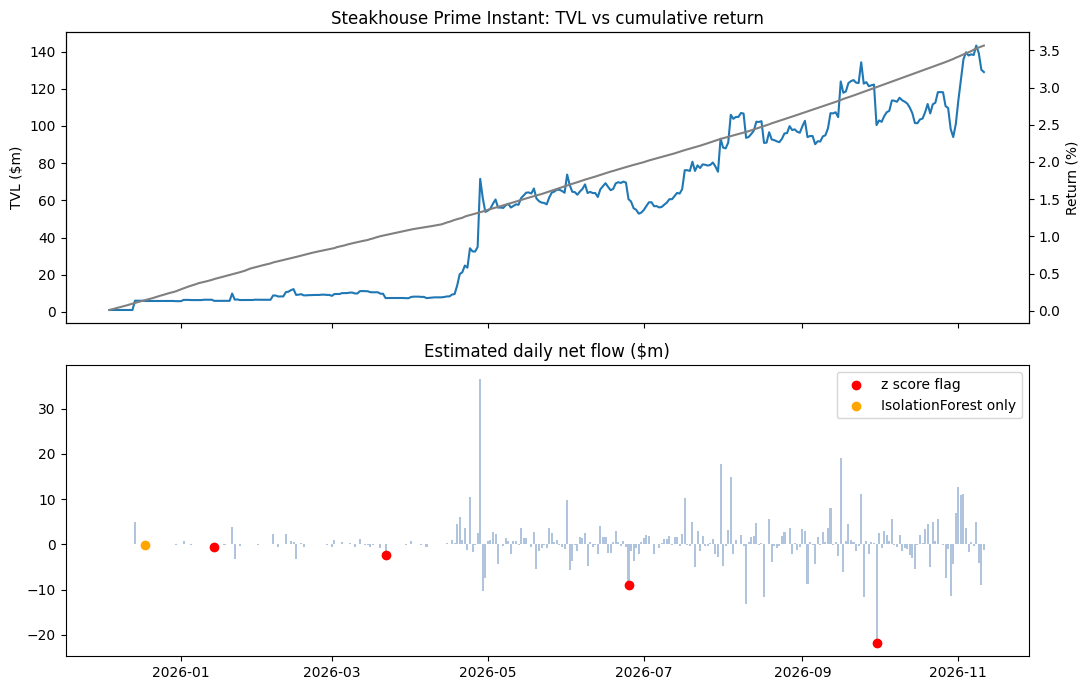

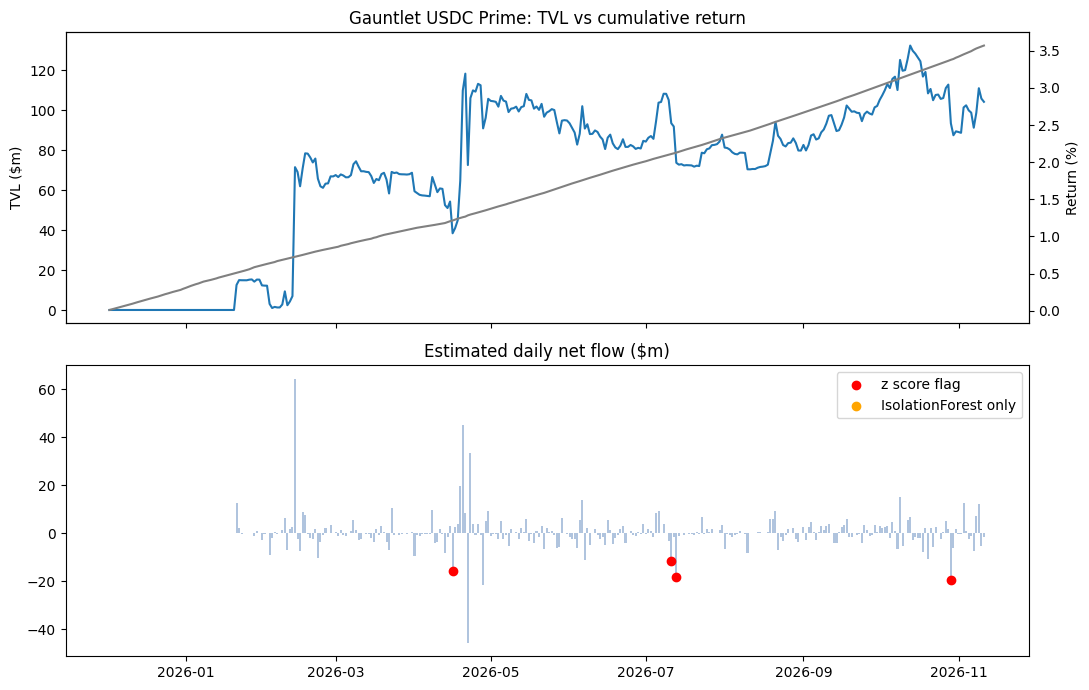

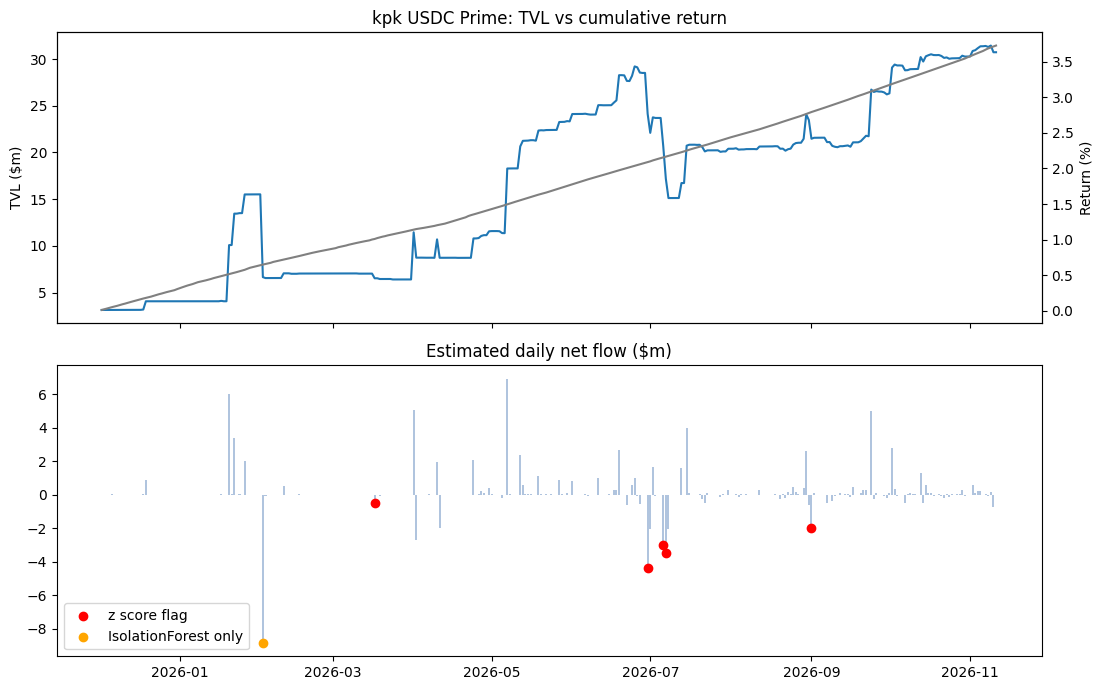

In [118]:
def plot(name, d):
    fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
    ax[0].plot(d.index, d["tvlUsd"] / 1e6, label="TVL ($m)")
    ax2 = ax[0].twinx()
    ax2.plot(d.index, d["cum_return"] * 100, color="gray", label="Cumulative return (%)")
    ax[0].set_title(f"{name}: TVL vs cumulative return")
    ax[0].set_ylabel("TVL ($m)"); ax2.set_ylabel("Return (%)")

    ax[1].bar(d.index, d["net_flow"] / 1e6, color="lightsteelblue")
    f = d[d["flag_z"]]; g = d[d["flag_if"] & ~d["flag_z"]]
    ax[1].scatter(f.index, f["net_flow"] / 1e6, color="red", label="z score flag", zorder=3)
    ax[1].scatter(g.index, g["net_flow"] / 1e6, color="orange", label="IsolationForest only", zorder=3)
    ax[1].set_title("Estimated daily net flow ($m)"); ax[1].legend()
    plt.tight_layout(); plt.show()

for name, d in out.items():
    plot(name, d)

In [119]:
for name, d in out.items():
    print(name)
    display(d[d["flag_z"] | d["flag_if"]][["tvlUsd", "net_flow", "z", "flag_z", "flag_if"]])

Steakhouse Prime Instant


,tvlUsd,net_flow,z,flag_z,flag_if
date,,,,,
2025-12-18,5845043,-1.514664e+05,NaN,False,True
2026-01-14,5925414,-5.998611e+05,-4.124493,True,False
2026-03-22,7403141,-2.367171e+06,-6.190602,True,False
2026-06-25,60667471,-8.880283e+06,-3.121171,True,False
2026-09-30,100484588,-2.178833e+07,-3.725030,True,False


Gauntlet USDC Prime


,tvlUsd,net_flow,z,flag_z,flag_if
date,,,,,
2026-04-16,38452871,-1.588119e+07,-4.337733,True,False
2026-07-11,93500885,-1.160229e+07,-3.073849,True,False
2026-07-13,73684645,-1.814494e+07,-4.573818,True,False
2026-10-29,93394055,-1.940976e+07,-4.127035,True,False


kpk USDC Prime


,tvlUsd,net_flow,z,flag_z,flag_if
date,,,,,
2026-02-02,6652707,-8.866548e+06,-2.318324,False,True
2026-03-17,6528626,-5.002449e+05,-79.444816,True,False
2026-06-30,24140620,-4.385741e+06,-7.008145,True,False
2026-07-06,20674450,-3.027150e+06,-3.024283,True,False
2026-07-07,17180164,-3.496291e+06,-3.415358,True,False
2026-09-01,21471559,-2.006781e+06,-3.817910,True,False


## Limits

1. TVL comes from DeFiLlama, not onchain data, and is measured in USD. Only USDC vaults are used so that price moves don't show up as flows.
2. apyBase is a smoothed annual figure, not the return earned each day, so return volatility looks lower than it really is.
3. The data is daily. A deposit and a withdrawal inside the same snapshot window cancel out. DeFiLlama snapshots at about 23:00 UTC, so onchain checks must use that window, not the calendar day.
4. Missing days are left blank, not filled in.
5. The z score can flag tiny moves when recent flows are close to zero. Gauntlet on 18 Jan flagged a $1,025 outflow from a $102k vault, and a minimum outflow filter of $250k removes it. kpk on 17 Mar shows a z of minus 79: the $500k outflow was real (about 7% of the vault), but the z value is inflated because the days before it were almost flat.
6. The opposite also happens: large inflows widen the baseline and hide the next outflow. Gauntlet's 45.71m outflow on 22 Apr, the largest in the sample, was missed by both methods for this reason.
7. There are no labelled anomalies, so precision can't be scored formally. Instead, five days were checked against Deposit and Withdraw events, and all five estimates matched within 0.1%. The 3 sigma threshold and 1% contamination are still assumptions.
8. Gauntlet's 92.89% max TVL drawdown comes from its first weeks, when TVL fell from 15.4m on 27 Jan to 1.1m on 4 Feb 2026. It has not been checked onchain.

## Next step

1. Build the baseline from outflow days only, or use a median based z score, so large inflows can't hide the next outflow. Fit IsolationForest on outflow days only for the same reason.
2. Automate the event check with web3.py and use convertToAssets() for the real share price, so every day is checked against onchain data, not just the flagged ones.